# Human Mobility in Yogyakarta
**Data engineering, analytics, dan visualization — dua sumber independen**

Periode: **1 Desember 2021–30 April 2022**, tanggal dan jam lokal WIB.

Notebook ini memeriksa kualitas data, menghasilkan tabel analitis, dan membahas hasil secara deskriptif.
Hasil grafik dan ringkasan disimpan dalam `figures/` dan `reports/`.
Tidak ada data sintetis yang digunakan untuk temuan.

Pertanyaan analisis:
1. Seberapa lengkap data mobilitas yang tersedia, dan bagaimana cakupannya berubah?
2. Bagaimana pola kehadiran per jam pada hari kerja dan akhir pekan?
3. Bagaimana komposisi kehadiran terpublikasi antar-kabupaten/kota?
4. Bagaimana pola proksi JogjaPulse berhubungan dengan enam kategori Google Mobility?
5. Pasangan asal–tujuan mana yang memiliki pangsa kunjungan teramati tertinggi pada periode OD yang lebih andal?

## 1. Sumber, cakupan, dan cara menjalankan

| Sumber independen | Data yang digunakan | Peran |
|---|---|---|
| [JogjaPulse, Widyawan et al. (2026)](https://doi.org/10.5281/zenodo.23157460) | Kehadiran kapanewon-jam; kunjungan OD bulanan; denominator perangkat asal | Pola jam, distribusi wilayah, pangsa kunjungan |
| [Google LLC, Community Mobility Reports](https://www.google.com/covid19/mobility/) | Ekstrak Indonesia 2021 dan 2022; hanya baris provinsi `ID-YO` | Perubahan terhadap baseline enam kategori tempat |

Beberapa CSV JogjaPulse berasal dari **satu sumber**. Google adalah sumber kedua.
Data cuaca/hari libur tidak digunakan dalam lingkup dua sumber ini.

Dari root repo, jalankan `python src/run_project.py` untuk mengunduh dan mengeksekusi notebook.
Atau jalankan `python src/download_data.py`, lalu **Run All** notebook ini dengan kernel Python environment proyek.
Untuk meninjau hasil yang sudah dieksekusi di GitHub, unduhan ulang tidak diperlukan.
Data mentah/olahan berukuran besar tidak dimasukkan ke Git; URL dan checksum tersedia di `reports/data_manifest.json`.

In [1]:
import sys, json
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'pipeline.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Buka notebook dari dalam folder repo.')
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from pipeline import build, RAW, PROCESSED, REPORTS, GOOGLE_METRICS
import analysis as a
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| NumPy:', np.__version__)

Python: 3.12.14 | pandas: 3.0.1 | NumPy: 2.3.5


## 2. Inspect data mentah dan asal-usulnya

Downloader menggunakan file sementara dan penggantian atomik; file gagal tidak diperlakukan sebagai cache berhasil.
File JogjaPulse diverifikasi dengan checksum dari API Zenodo. Semua sumber diberi SHA-256 lokal.
Google tidak menyediakan checksum penerbit pada endpoint CSV; hash lokal mengidentifikasi versi unduhan,
bukan bukti checksum independen dari penerbit.

In [2]:
manifest_path = RAW / 'manifest.json'
if not manifest_path.exists():
    raise FileNotFoundError('Jalankan python src/download_data.py terlebih dahulu.')
manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
display(pd.DataFrame(manifest['files'])[['source', 'path', 'bytes', 'publisher_checksum']])
raw_presence = pd.read_csv(RAW / 'jogjapulse_presence_kapanewon_hourly.csv', dtype=str)
display(raw_presence.head())
print('Baris mentah JogjaPulse:', len(raw_presence))

,source,path,bytes,publisher_checksum
0,JogjaPulse,data/raw/jogjapulse_README.md,19448,md5:ac30f40e0e021cb2b131d529d782c75b
1,JogjaPulse,data/raw/jogjapulse_od_home_visits_kapanewon_m...,806483,md5:5857291c608dd5335f6d8833c1ec7b7a
2,JogjaPulse,data/raw/jogjapulse_od_origin_homes_monthly.csv,21387,md5:d14368c48d3937c9146ed9054aee3c79
3,JogjaPulse,data/raw/jogjapulse_presence_kapanewon_hourly.csv,12189908,md5:90a4a8ae6eb68abc68f7a1021a51cce8
4,JogjaPulse,data/raw/jogjapulse_tier1_summary.csv,230,md5:d391339521ce3714f1616c430512b0e0
5,Google Community Mobility,data/raw/google_2021_ID_Region_Mobility_Report...,1198710,NaN
6,Google Community Mobility,data/raw/google_2022_ID_Region_Mobility_Report...,930571,NaN


,kab_code,kab_kota,kapanewon_code,kapanewon,date,hour,n_maids,n_pings
0,34.01,KULON PROGO,34.01.01,TEMON,2021-12-01,0,16,66
1,34.01,KULON PROGO,34.01.02,WATES,2021-12-01,0,58,101
2,34.01,KULON PROGO,34.01.03,PANJATAN,2021-12-01,0,11,32
3,34.01,KULON PROGO,34.01.04,GALUR,2021-12-01,0,9,50
4,34.01,KULON PROGO,34.01.05,LENDAH,2021-12-01,0,14,74


Baris mentah JogjaPulse: 230418


## 3. Cleaning, validasi, dan integrasi

Kode transformasi lengkap tersedia di `src/pipeline.py`. Notebook memanggil fungsi yang sama dengan CLI.

- Kolom wajib, tipe data, rentang jam 0–23, ambang publikasi perangkat ≥5, dan konsistensi kode wilayah diperiksa.
- Duplikasi persis dihapus dan dihitung; nilai berbeda pada natural key yang sama menghentikan proses.
- Key presence: `(kapanewon_code, date, hour)`; key OD: `(month, origin_code, dest_code)`.
- Google difilter `ID`, `ID-YO`, tanpa subwilayah/metro. Key integrasi: tanggal provinsi, **one-to-one**.
- Semua 151 tanggal wajib tersedia; kegagalan join menghentikan proses.
- Kerangka 78 kapanewon × 151 hari dibuat agar unit-hari tidak terpublikasi tetap terlihat.
  Nilai kehadiran yang hilang tetap **NA**; angka nol hanya digunakan untuk **jumlah slot terpublikasi**.

In [3]:
outputs, quality = build()
display(pd.DataFrame([{'table': name, 'rows': len(frame), 'columns': len(frame.columns)} for name, frame in outputs.items()]))
display(Markdown('**Audit kualitas**'))
print(json.dumps(quality, indent=2))
joined = outputs['integrated_daily']
display(joined.head())
assert len(joined) == 151 and joined.date.is_unique

Prepared 7 tables; joined 151 days with no unmatched dates.


,table,rows,columns
0,presence_hourly_clean,230418,16
1,kapanewon_daily,11778,18
2,diy_daily,151,13
3,regency_daily,755,7
4,google_diy_daily,151,7
5,integrated_daily,151,19
6,od_monthly_clean,9894,14


**Audit kualitas**

{
  "period": {
    "start": "2021-12-01",
    "end": "2022-04-30",
    "days": 151
  },
  "presence": {
    "input_rows": 230418,
    "exact_duplicates_removed": 0,
    "outside_period_rows": 0,
    "output_rows": 230418,
    "kapanewon": 78,
    "dates": 151,
    "minimum_daily_coverage_pct": 40.491452991452995,
    "complete_unit_days": 5794,
    "unpublished_unit_days": 327
  },
  "google": {
    "input_rows": 653,
    "exact_duplicates_removed": 0,
    "all_indonesia_input_rows": 22855,
    "other_region_or_level_rows_excluded": 22202,
    "outside_period_rows": 502,
    "output_rows": 151,
    "missing_by_column": {
      "date": 0,
      "google_retail_and_recreation_pct": 0,
      "google_grocery_and_pharmacy_pct": 0,
      "google_parks_pct": 0,
      "google_transit_stations_pct": 0,
      "google_workplaces_pct": 0,
      "google_residential_pct": 0
    }
  },
  "od": {
    "input_rows": 9894,
    "exact_duplicates_removed": 0,
    "output_rows": 9894,
    "missing_denominat

,date,published_device_presence_units,published_pings,published_slots,complete_kapanewon_days,daytime_share_pct,...,google_retail_and_recreation_pct,google_grocery_and_pharmacy_pct,google_parks_pct,google_transit_stations_pct,google_workplaces_pct,google_residential_pct
0,2021-12-01,"104,064.000","476,370.000",1767,50,47.154,...,8,21,-3,-22,-14,7
1,2021-12-02,"188,671.000","648,795.000",1758,52,51.533,...,10,24,5,-23,-13,7
2,2021-12-03,"212,018.000","679,472.000",1779,62,53.413,...,6,15,-3,-25,-13,9
3,2021-12-04,"213,261.000","632,842.000",1752,56,51.977,...,4,17,1,-13,-5,7
4,2021-12-05,"198,758.000","590,834.000",1746,61,52.547,...,9,17,7,-14,-6,7


## 4. Definisi metrik dan batas pengukuran

**Unit kehadiran perangkat** adalah penjumlahan `n_maids` pada slot lokasi-jam terpublikasi.
Perangkat yang sama bisa dihitung pada beberapa jam dan lokasi; hasilnya **bukan perangkat unik harian, penduduk, atau perjalanan**.

Untuk kapanewon-hari dengan 24 jam terpublikasi:

$$\text{pangsa jam }h = 100\times\frac{n_{maids,h}}{\sum_{j=0}^{23} n_{maids,j}}$$

$$\text{pangsa siang} = 100\times\frac{\sum_{h=8}^{17} n_{maids,h}}{\sum_{h=0}^{23}n_{maids,h}}$$

Pangsa siang DIY adalah rata-rata pangsa siang kapanewon yang lengkap pada hari itu, dengan bobot sama.
Profil jam dirata-ratakan antar-kapanewon dalam tanggal, lalu antar-tanggal agar hari berbobot sama.
Kapanewon yang masuk dapat berubah: normalisasi tidak menyelesaikan seluruh bias komposisi.

Pangsa wilayah adalah bagian dari **total unit kehadiran terpublikasi**, bukan bagian dari populasi.
Cakupan adalah slot terpublikasi / (78 × 24) per hari; tidak sama dengan representativitas penduduk.

Google mempertahankan perubahan (%) dari median **hari sejenis** pada 3 Januari–6 Februari 2020.
Nilai ini tidak langsung dibandingkan dengan jumlah perangkat atau antar-kategori sebagai jumlah orang.
Residential terutama terkait durasi di rumah. Nilai Google kosong tidak diinterpolasi.
Lihat [dokumentasi Google](https://www.google.com/covid19/mobility/data_documentation.html).

## 5. Cakupan data dan perubahan sampel

Dokumentasi sumber menandai perubahan sampel 1 Januari dan 16 Februari, anomali 8 Maret, dan kualitas OD lebih rendah pada Maret–April.
Penurunan hitungan mentah tidak dapat diartikan sebagai penurunan mobilitas penduduk.
Flag tersebut dipertahankan dalam tabel analitis. Baris tidak terpublikasi tidak diasumsikan bernilai nol.

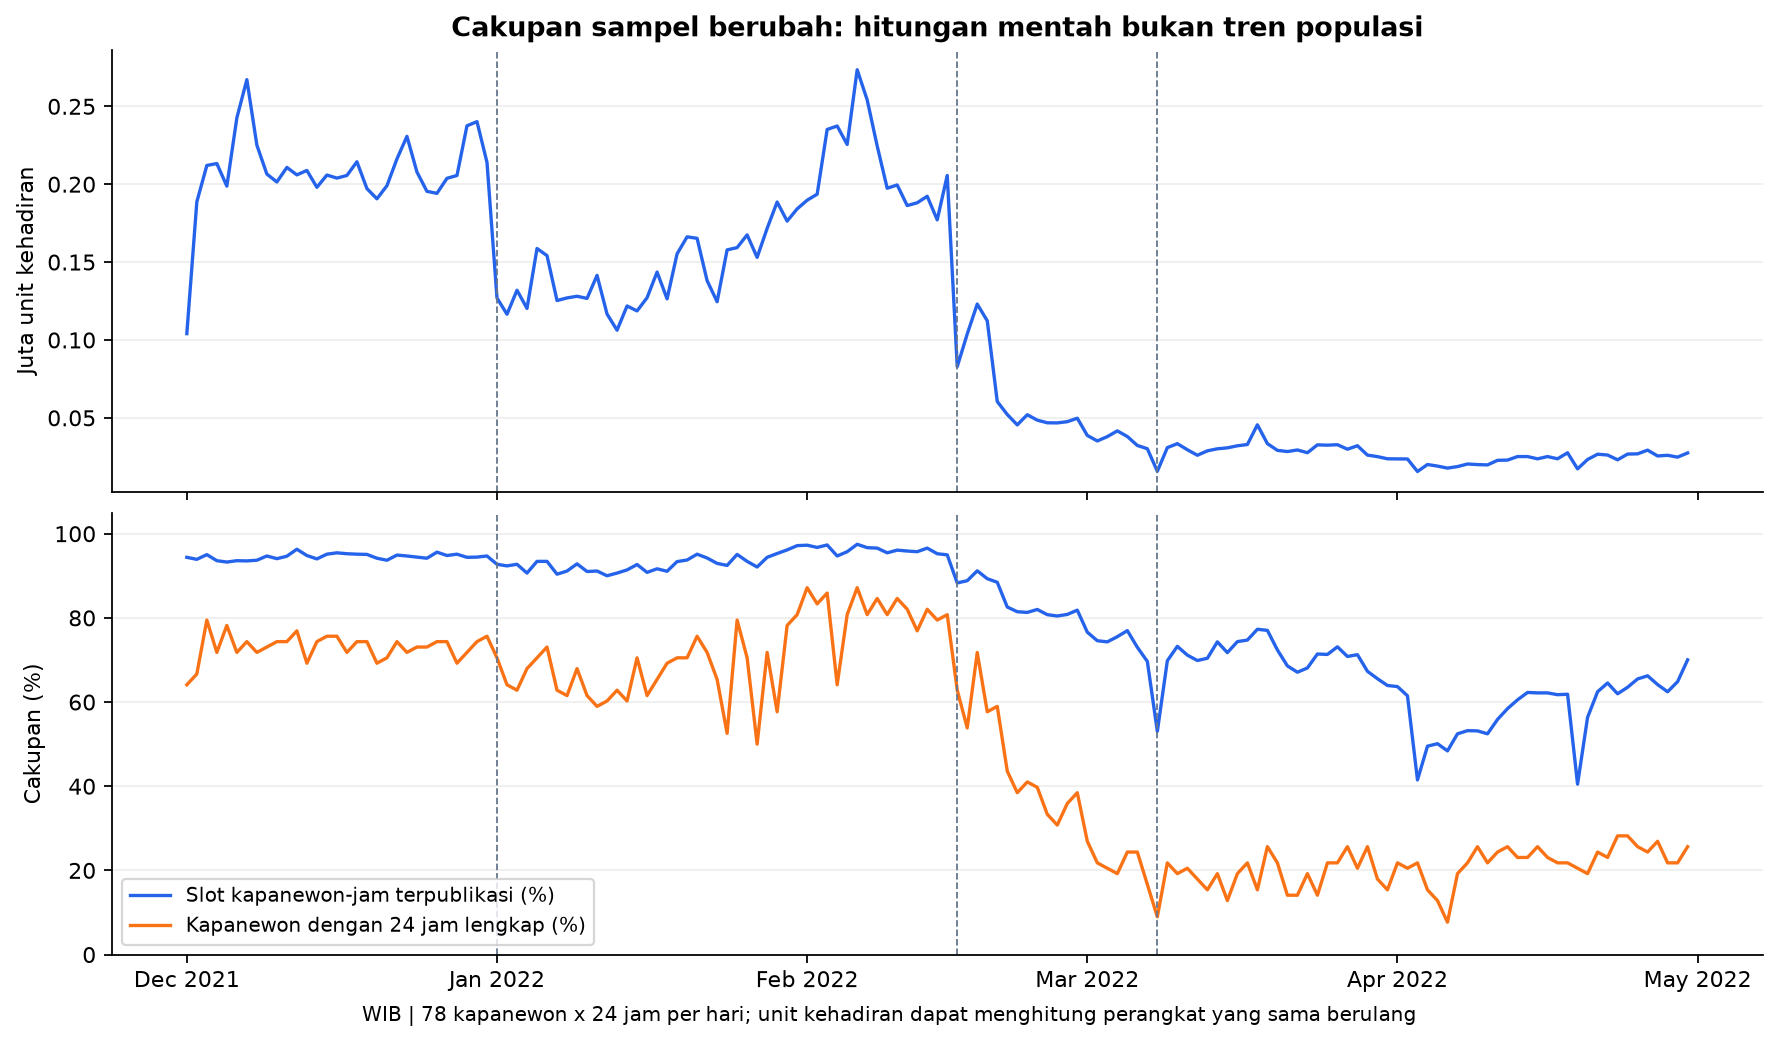

,mean_coverage_pct,mean_complete_kapanewon
date,,
2021-12,94.546,56.968
2022-01,92.764,52.000
2022-02,90.709,50.893
2022-03,71.245,15.194
2022-04,58.453,17.333


In [4]:
fig = a.quality_figure(outputs['diy_daily'])
display(Image(filename=str(a.FIGURES / '01_sample_coverage.png')))
plt.close(fig)
display(joined.groupby(joined.date.dt.to_period('M')).agg(
    mean_coverage_pct=('coverage_pct', 'mean'),
    mean_complete_kapanewon=('complete_kapanewon_days', 'mean')))

## 6. Pola per jam: hari kerja dan akhir pekan

Gunakan unit-hari lengkap agar jam malam yang tersupresi tidak dianggap nol. Tanggal 8 Maret dikecualikan.
Weekday berarti Senin–Jumat; Weekend berarti Sabtu–Minggu, **tanpa klasifikasi hari libur**.
Pangsa jam menunjukkan distribusi kehadiran dalam sehari, bukan frekuensi perjalanan.

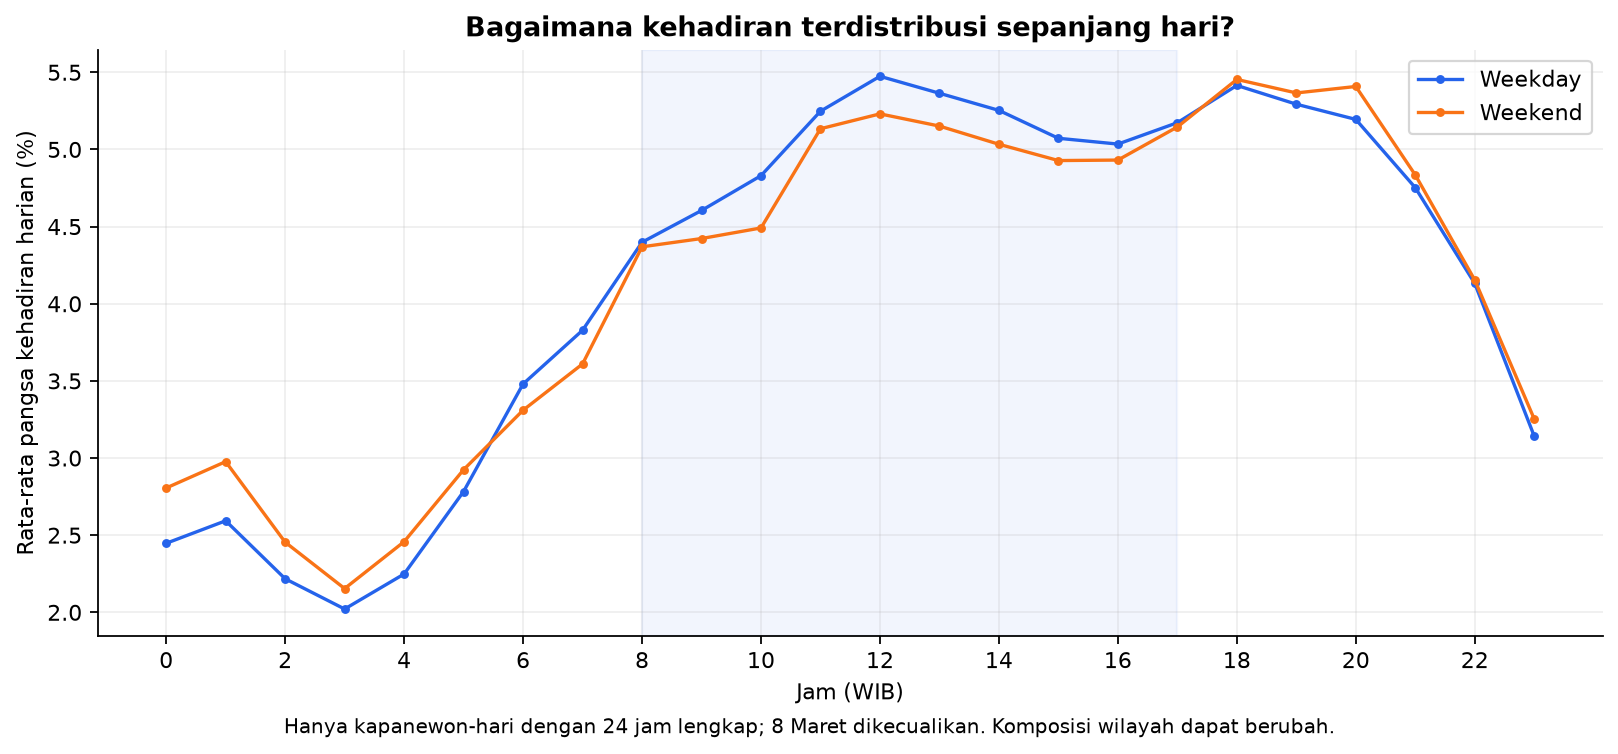

day_type,Weekday,Weekend
hour,,
0,2.447,2.806
1,2.593,2.977
2,2.218,2.455
3,2.021,2.154
4,2.248,2.458
5,2.783,2.924
6,3.480,3.310
7,3.828,3.610
8,4.399,4.369


In [5]:
fig, profile = a.hourly_figure(outputs['presence_hourly_clean'])
display(Image(filename=str(a.FIGURES / '02_hourly_profile.png')))
plt.close(fig)
display(profile)

## 7. Distribusi antar-kabupaten/kota

Rata-rata bergerak 7 hari dipakai untuk membantu membaca komposisi, dengan syarat tujuh hari tersedia.
Selalu baca bersama cakupan: perubahan pangsa dapat berasal dari perubahan sampel dan suppression,
bukan hanya perpindahan aktivitas. Tidak ada klaim bahwa grafik mengukur pangsa penduduk.

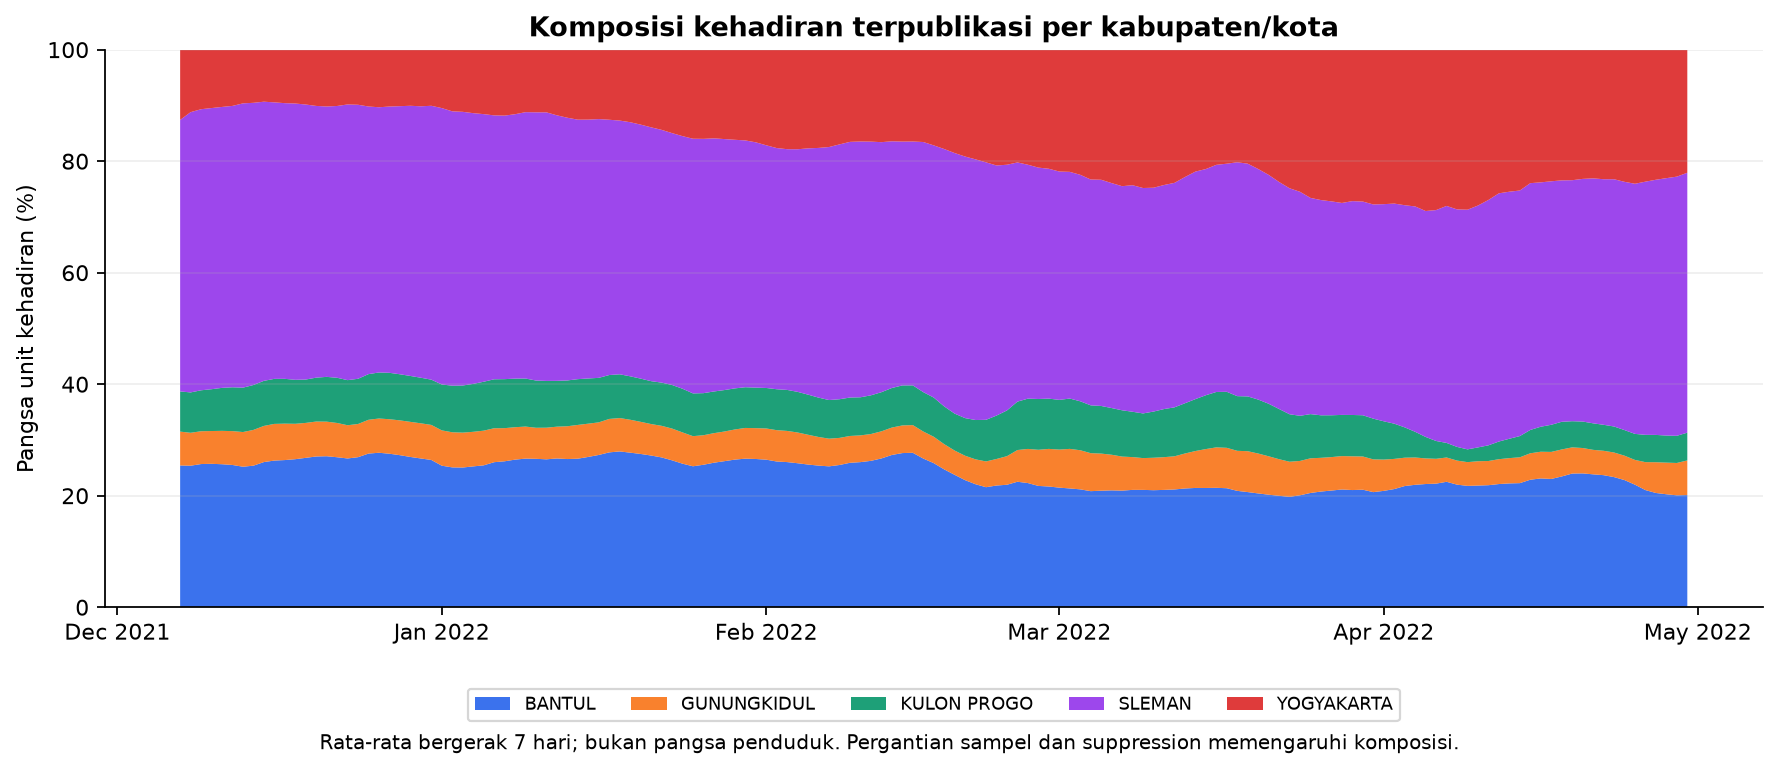

In [6]:
fig = a.regency_figure(outputs['regency_daily'])
display(Image(filename=str(a.FIGURES / '03_regency_composition.png')))
plt.close(fig)

## 8. Google Community Mobility sebagai sumber kedua

Grafik berikut memakai baris provinsi DIY saja. Garis tipis adalah data asli; garis tebal adalah rerata 7 hari.
Setiap kategori memiliki baseline sendiri. Perbedaan persentase antar-kategori tidak memberi jumlah pengunjung.

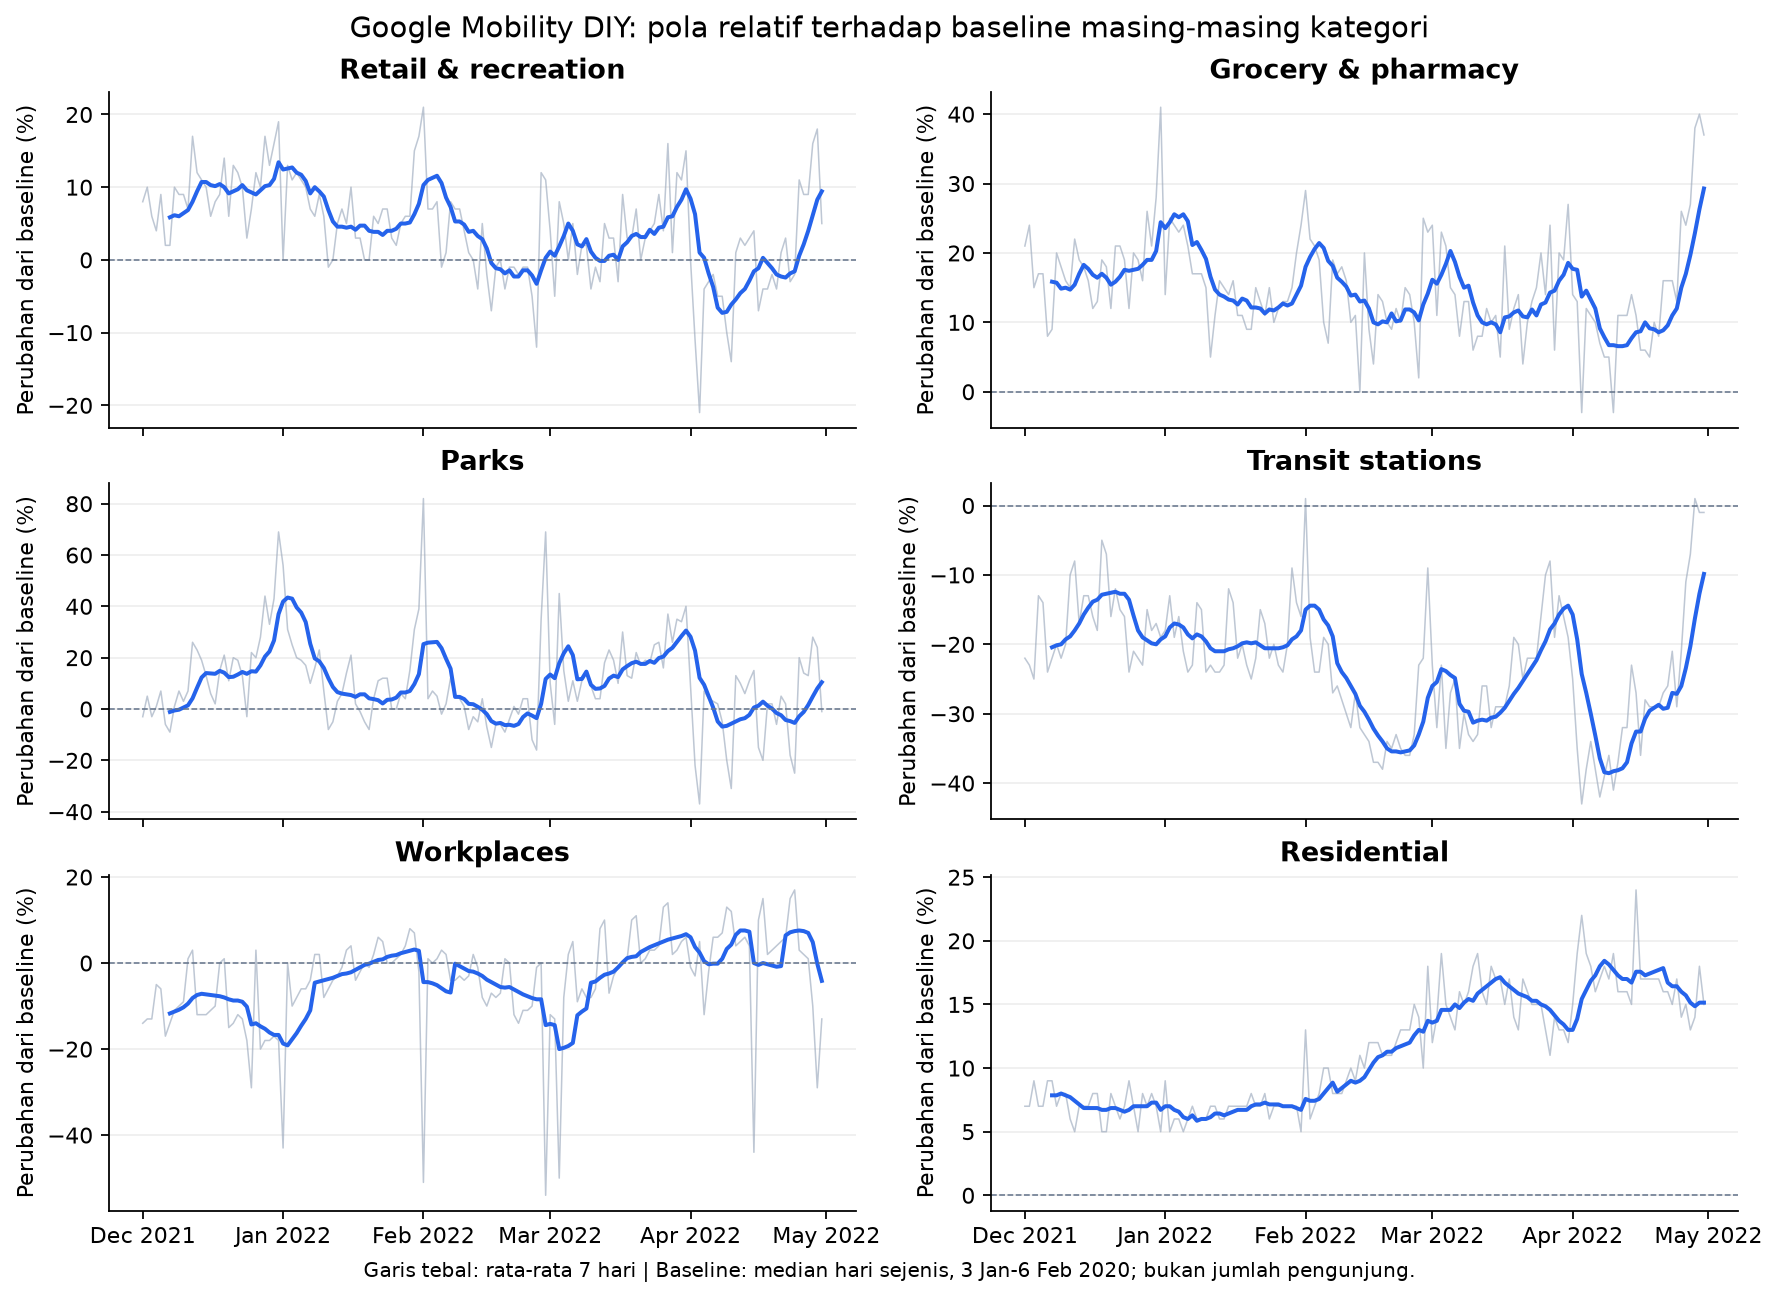

In [7]:
fig = a.google_figure(outputs['google_diy_daily'])
display(Image(filename=str(a.FIGURES / '04_google_mobility.png')))
plt.close(fig)

## 9. Analisis gabungan dua sumber dan pemeriksaan sensitivitas

Pangsa kehadiran siang JogjaPulse dibandingkan dengan enam kategori Google pada tanggal yang sama.
Kedua sumber mengukur konsep dan sampel berbeda; hubungan ini **eksploratif**, bukan validasi jumlah perjalanan.

Tabel membandingkan korelasi Pearson mentah, korelasi setelah pengurangan rerata dalam kelompok hari-dalam-minggu × rezim sampel,
dan korelasi **selisih 7 hari**. Selisih tujuh hari mempertahankan hari sejenis pada baseline Google.
Pasangan yang melintasi pergantian rezim dikecualikan. 8 Maret dan pasangan dengan nilai kosong dikecualikan.
Periode sebelum 16 Februari juga dihitung untuk memeriksa sensitivitas terhadap penurunan sampel berikutnya.

Pemeriksaan tambahan menahan keanggotaan wilayah tetap pada kapanewon yang lengkap di seluruh hari non-anomali.
Panel ini hanya mencakup empat kapanewon pada data saat ini, sehingga juga tidak representatif seluruh DIY.

Z-score hanya menyetarakan skala tampilan. Korelasi tidak mengendalikan semua perubahan sampel,
musim, dan autokorelasi; tidak dihitung p-value atau disimpulkan sebab-akibat.

,window,category,method,n_pairs,pearson_r
0,all_valid,Retail & recreation,raw,150,0.147
1,all_valid,Retail & recreation,weekday_regime_adjusted,150,-0.268
2,all_valid,Retail & recreation,7day_difference,128,-0.269
3,all_valid,Grocery & pharmacy,raw,150,0.048
4,all_valid,Grocery & pharmacy,weekday_regime_adjusted,150,-0.176
5,all_valid,Grocery & pharmacy,7day_difference,128,-0.214
6,all_valid,Parks,raw,150,-0.060
7,all_valid,Parks,weekday_regime_adjusted,150,-0.277
8,all_valid,Parks,7day_difference,128,-0.276
9,all_valid,Transit stations,raw,150,-0.009


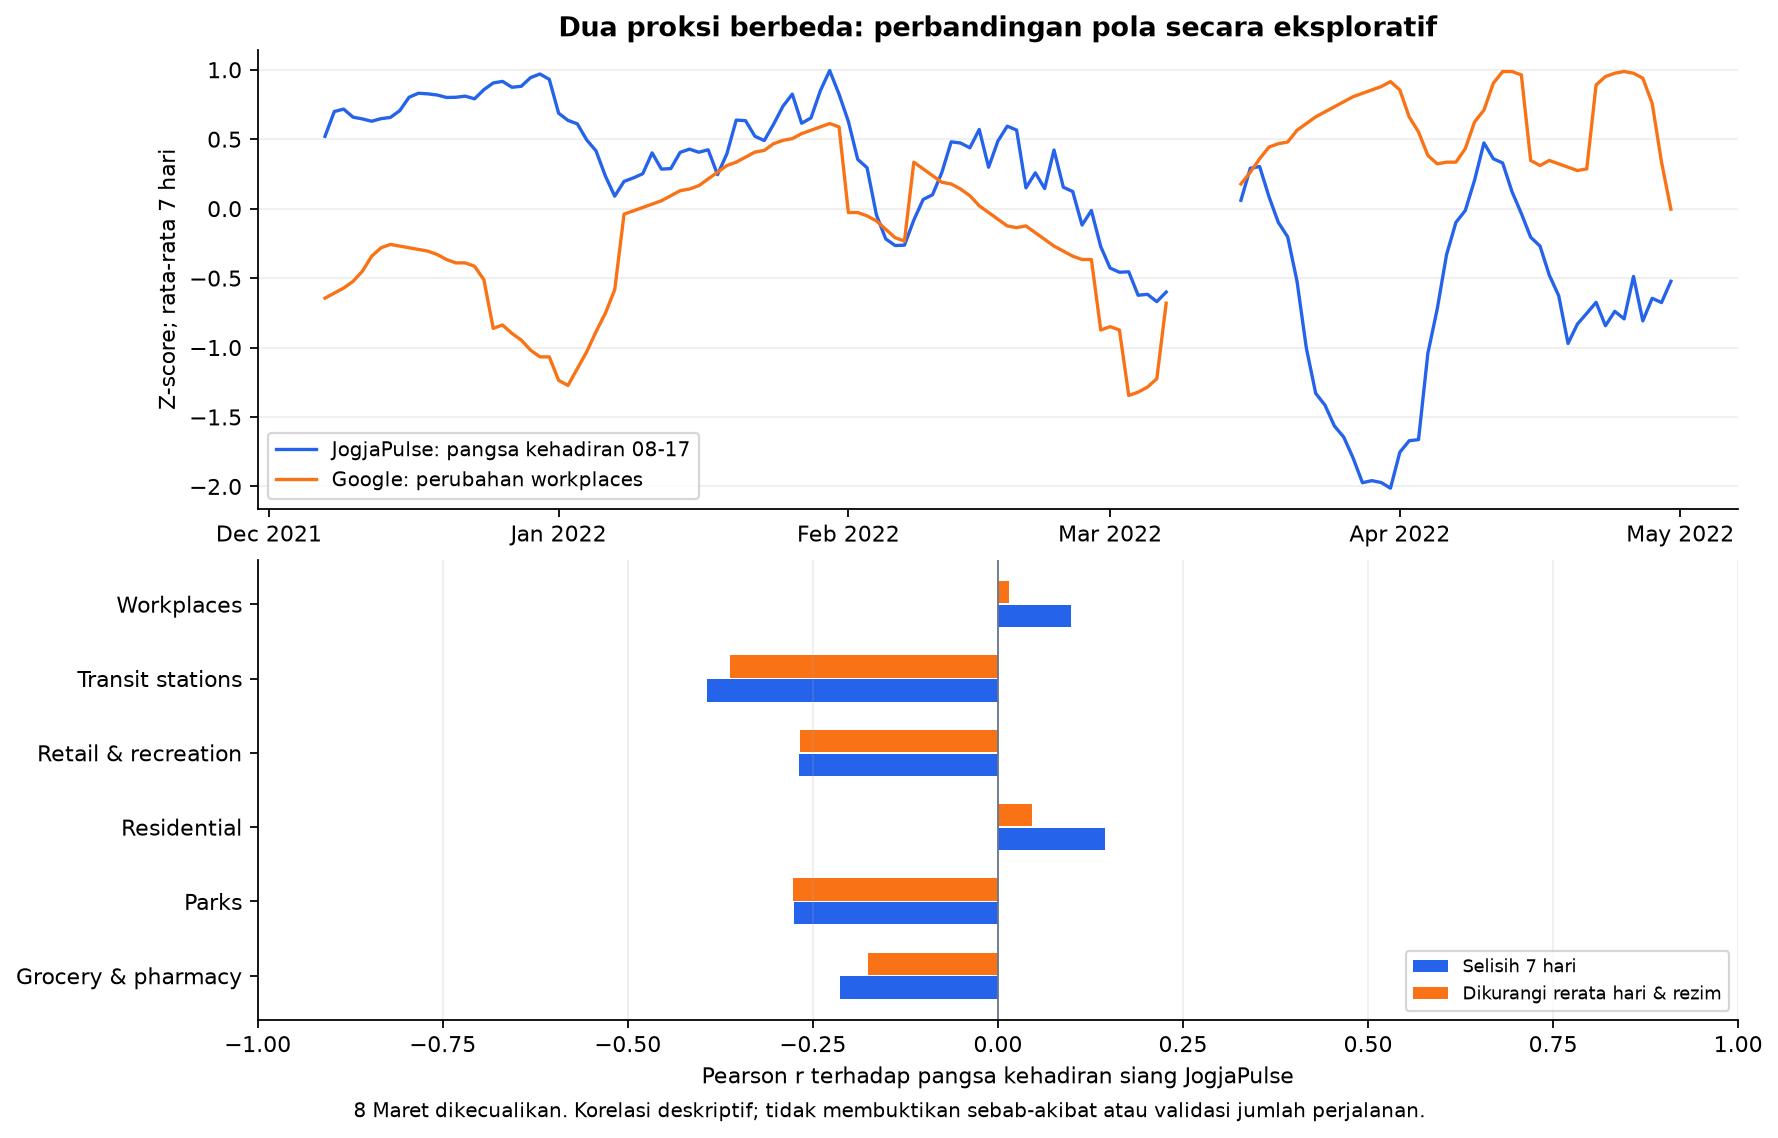

In [8]:
correlations = a.correlation_tables(joined)
display(correlations.round(3))
fig = a.comparison_figure(joined, correlations)
display(Image(filename=str(a.FIGURES / '05_two_source_comparison.png')))
plt.close(fig)

In [9]:
panel_names, panel_correlations = a.fixed_panel_sensitivity(outputs)
display(Markdown('**Sensitivitas: panel wilayah tetap, seluruh hari non-anomali**'))
display(panel_names)
display(panel_correlations.query("window == 'all_valid' and method == '7day_difference'"))

**Sensitivitas: panel wilayah tetap, seluruh hari non-anomali**

,kapanewon_code,kapanewon,kab_kota
22,34.02.12,BANGUNTAPAN,BANTUL
42,34.04.07,DEPOK,SLEMAN
48,34.04.13,SLEMAN,SLEMAN
62,34.71.10,GONDOMANAN,YOGYAKARTA


,window,category,method,n_pairs,pearson_r
2,all_valid,Retail & recreation,7day_difference,128,-0.301
5,all_valid,Grocery & pharmacy,7day_difference,128,-0.301
8,all_valid,Parks,7day_difference,128,-0.294
11,all_valid,Transit stations,7day_difference,128,-0.395
14,all_valid,Workplaces,7day_difference,128,0.154
17,all_valid,Residential,7day_difference,128,0.161


## 10. Tambahan JogjaPulse: pangsa kunjungan asal–tujuan

$$\text{pangsa kunjungan}_{i,j,m}=100\times\frac{\text{perangkat asal }i\text{ yang teramati di }j}{\text{perangkat ber-home }i\text{ yang teramati pada siang hari}}$$

Analisis dibatasi **Desember 2021–Februari 2022**, antar-kapanewon, dan pasangan terpublikasi pada ketiga bulan.
Ranking menggunakan rata-rata pangsa tiap pasangan. Satu perangkat bisa mengunjungi beberapa tujuan;
pangsa tidak dijumlahkan antar-tujuan. Grafik ini adalah kunjungan perangkat teramati, bukan jumlah trip,
dan tidak membandingkan perubahan populasi antarbulan.

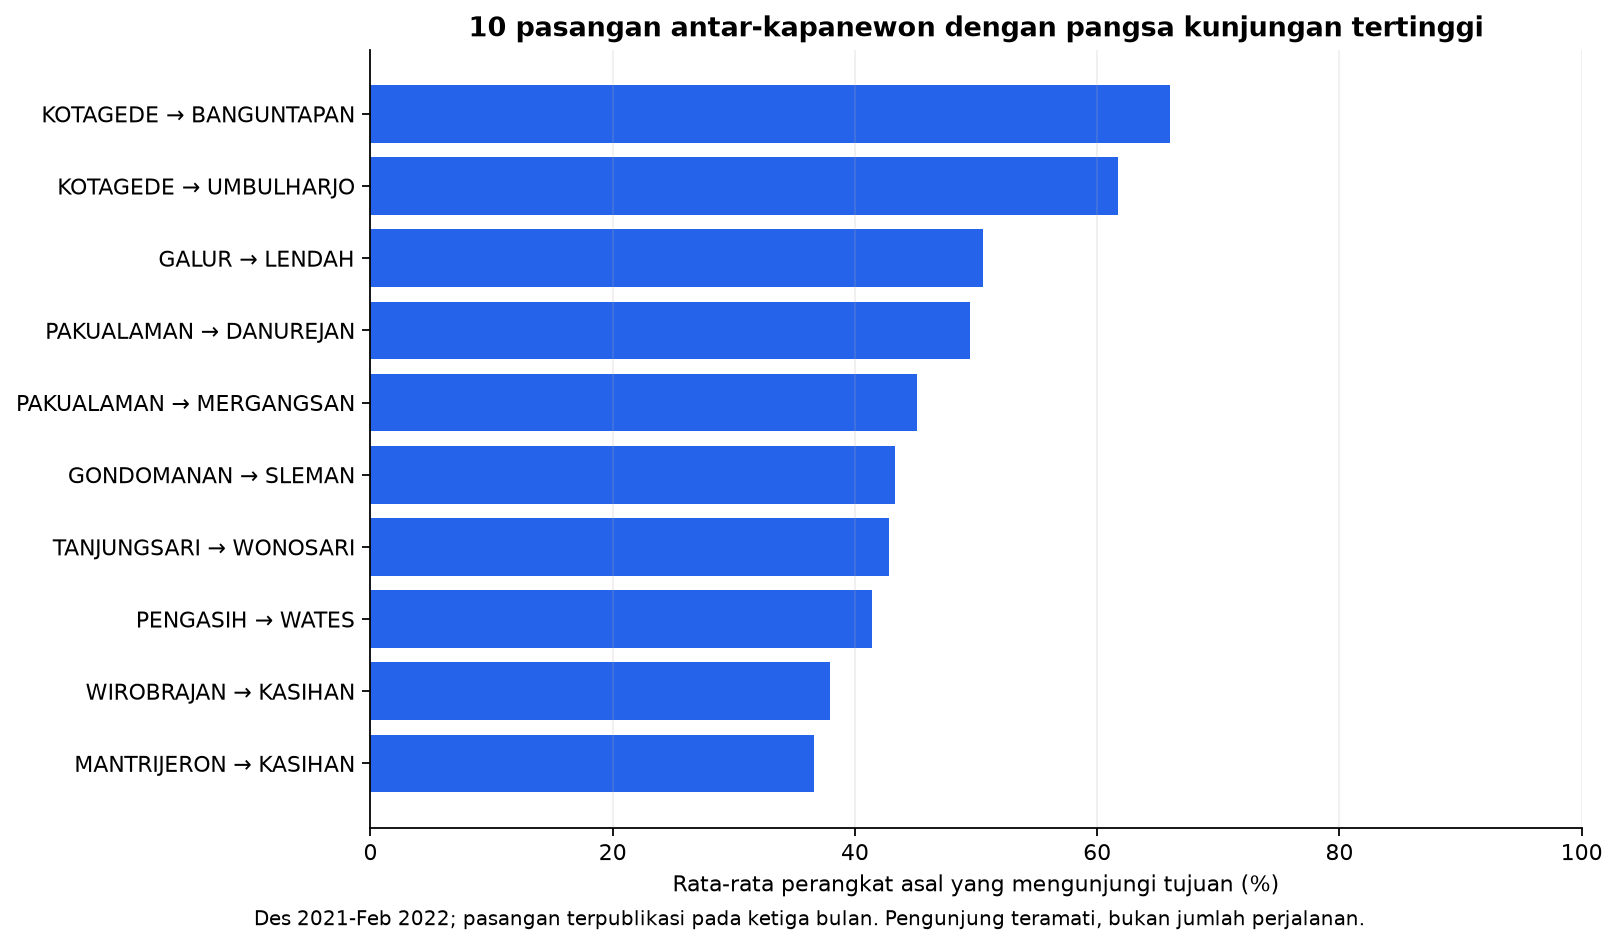

,origin_kapanewon,dest_kapanewon,months_published,mean_visit_share_pct
3194,KOTAGEDE,BANGUNTAPAN,3,66.040
3227,KOTAGEDE,UMBULHARJO,3,61.729
129,GALUR,LENDAH,3,50.534
3066,PAKUALAMAN,DANUREJAN,3,49.484
3071,PAKUALAMAN,MERGANGSAN,3,45.125
3025,GONDOMANAN,SLEMAN,3,43.310
1642,TANJUNGSARI,WONOSARI,3,42.851
255,PENGASIH,WATES,3,41.372
2881,WIROBRAJAN,KASIHAN,3,37.919
2916,MANTRIJERON,KASIHAN,3,36.589


In [10]:
fig, top = a.od_figure(outputs['od_monthly_clean'])
display(Image(filename=str(a.FIGURES / '06_od_visit_shares.png')))
plt.close(fig)
display(top[['origin_kapanewon', 'dest_kapanewon', 'months_published', 'mean_visit_share_pct']].sort_values('mean_visit_share_pct', ascending=False))

## 11. Temuan yang dihitung dari data

Sel berikut memperbarui ringkasan, tabel korelasi, audit bulanan, dan preview integrasi di `reports/`.
Interpretasi dibatasi pada sampel yang tersedia dan tidak dipakai sebagai klaim populasi atau kausalitas.

In [11]:
summary = a.summarize(outputs, correlations, profile, top)
display(Markdown((REPORTS / 'findings.md').read_text(encoding='utf-8')))

# Hasil analisis mobilitas DIY

Analisis deskriptif dua sumber independen, 1 Desember 2021-30 April 2022 (WIB).
Angka di bawah dihasilkan oleh `src/analysis.py`, bukan ditulis sebelum data diperiksa.

## Data dan validasi

- JogjaPulse: 230,418 baris kapanewon-jam, 78 kapanewon.
- Integrasi dengan Google DIY: 151 hari, satu baris per tanggal; tidak ada tanggal gagal join.
- Duplikasi persis yang dihapus pada presence: 0.
- Cakupan minimum slot kapanewon-jam: 40.5%.
- Kapanewon dengan data 24 jam lengkap per hari: 6-68 dari 78.
- Nilai Google yang kosong tetap kosong; lihat `data_quality.json` untuk rincian per kolom.

## Temuan

1. Pangsa kehadiran siang (08-17 WIB) rata-rata 50.45% pada hari kerja dan 48.84% pada akhir pekan, selisih -1.62 poin persentase. Ini adalah pembagian unit kehadiran sepanjang hari, bukan persentase orang yang bepergian. Angka menggunakan kapanewon-hari lengkap, pembobotan merata per kapanewon dalam hari lalu per hari, dan mengecualikan 8 Maret.
2. Puncak profil jam rata-rata: pukul 12 WIB pada hari kerja dan 18 WIB pada akhir pekan. Komposisi kapanewon lengkap dapat berbeda antarhari, sehingga pola bersifat deskriptif.
3. Korelasi selisih 7 hari dengan nilai absolut terbesar terdapat pada kategori Google **Transit stations**: r = -0.393, n = 128. Pemilihan nilai terbesar dari enam kategori bersifat eksploratif. Bandingkan seluruh kategori, penyesuaian hari/rezim, dan periode sebelum 16 Februari pada `correlations.csv`; jangan menafsirkannya sebagai validasi atau kausalitas.
4. Analisis OD dibatasi Desember-Februari. Grafik merangking rata-rata pangsa kunjungan tiap pasangan asal-tujuan yang terpublikasi pada ketiga bulan. Perangkat yang sama dapat mengunjungi beberapa tujuan; pangsa antar-tujuan tidak dijumlahkan menjadi total perjalanan.
5. Hanya **4 kapanewon** memiliki data 24 jam lengkap pada seluruh 150 hari non-anomali. Pada panel wilayah tetap ini, korelasi selisih 7 hari untuk kategori Transit stations adalah r = -0.395 (n = 128). Bandingkan dengan r = -0.393 pada panel yang berubah. Perbandingan ini memeriksa sensitivitas terhadap komposisi; kemiripan korelasi satu kategori tidak membuktikan tidak ada bias, dan panel kecil ini tidak mewakili seluruh DIY. Anggota dan semua korelasinya disimpan di `fixed_panel_members.csv` dan `fixed_panel_correlations.csv`.

## Batas interpretasi

Jumlah sampel JogjaPulse berubah pada 1 Januari dan 16 Februari; 8 Maret ditandai sebagai anomali. Periode Maret-April memiliki cakupan lebih lemah dan OD ditandai reduced quality. Normalisasi mengurangi pengaruh skala sampel, tetapi tidak menghilangkan bias perubahan komposisi. Slot yang tidak dipublikasikan bukan nol. Cakupan dalam laporan dihitung terhadap kerangka 78 x 24 slot per hari, bukan persentase penduduk yang terwakili.

Google mengukur perubahan kunjungan/durasi relatif terhadap median hari sejenis pada 3 Januari-6 Februari 2020. Residential terutama terkait durasi di rumah. JogjaPulse mengukur kehadiran perangkat dari sumber SDK berbeda. Kedua metrik tidak setara; z-score hanya membantu melihat pola. Selisih 7 hari menjaga kecocokan hari dalam minggu, melewati batas rezim sampel dikecualikan. Autokorelasi, musim, pemilihan sampel dan kategori tidak dikendalikan sepenuhnya; tidak dihitung p-value atau klaim signifikansi.

## Sumber

- Widyawan et al. (2026), JogjaPulse, https://doi.org/10.5281/zenodo.23157460 (CC BY 4.0; lihat metadata record).
- Google LLC, Google COVID-19 Community Mobility Reports, https://www.google.com/covid19/mobility/ (versi unduhan dicatat 2026-11-16). Dokumentasi: https://www.google.com/covid19/mobility/data_documentation.html dan https://support.google.com/covid19-mobility/answer/9824897.
- URL unduhan, SHA-256 lokal dan checksum penerbit jika tersedia: `data_manifest.json`.
